# Chapter 4. Drawing the best line

*Linear regression: fit, coefficients in units, residuals.*

Kalpa's Indiranagar store wants to know how a member's spend moves with how often they visit. Six members, invented for teaching, are enough to see the whole idea: a line through the points, a slope in rupees per visit, and the leftovers (residuals) that say what the line missed.

By the end you can fit a line by hand on six points, get the same line from scikit-learn, read the slope in rupees, and say why "best" means the smallest total of squared residuals.

**Search terms:** linear regression explained, least squares, residuals, slope and intercept, StatQuest linear regression.

In [1]:
# Tools for this notebook, and one helper that prints a check as PASS or FAIL.
import io, zipfile, pathlib, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

def check(label, ok):
    print(("PASS  " if ok else "FAIL  ") + label)

In [2]:
# Six members of one Kalpa store, invented for teaching: visits last month and spend this month.
store = pd.DataFrame({"visits": [1, 2, 3, 4, 5, 6], "spend_rs": [290, 450, 500, 700, 750, 910]})
print(store.to_string(index=False))

 visits  spend_rs
      1       290
      2       450
      3       500
      4       700
      5       750
      6       910


## Which line is "best"?

Before any code, draw a line by eye. Most people join the first and last points, which gives a slope of (910 minus 290) / 5 = Rs 124 per visit. The line any model must beat is the flat one at the mean spend, Rs 600, which ignores visits entirely.

**Predict before you run.** Which line leaves the smallest total of squared misses? (a) the flat mean line (b) the line through the first and last points (c) neither: a third line beats both

In [3]:
# Least squares by hand: slope = sum of (x - mean x)(y - mean y) / sum of (x - mean x) squared.
x, y = store["visits"], store["spend_rs"]
dx, dy = x - x.mean(), y - y.mean()
slope = (dx * dy).sum() / (dx ** 2).sum()
intercept = y.mean() - slope * x.mean()
print(f"mean visits {x.mean()}, mean spend Rs {y.mean():.0f}")
print(f"sum of dx*dy = {(dx * dy).sum():.0f}, sum of dx squared = {(dx ** 2).sum():.1f}")
print(f"slope = Rs {slope:.0f} per visit, intercept = Rs {intercept:.0f}")

def sse(a, b):
    return float(((y - (a + b * x)) ** 2).sum())

lines = {"flat mean line": (y.mean(), 0.0), "first-to-last by eye": (166.0, 124.0), "least squares": (intercept, slope)}
for name, (a, b) in lines.items():
    print(f"{name:22s} spend = {a:5.0f} + {b:5.0f} x visits   sum of squared residuals {sse(a, b):9,.0f}")

mean visits 3.5, mean spend Rs 600
sum of dx*dy = 2100, sum of dx squared = 17.5
slope = Rs 120 per visit, intercept = Rs 180
flat mean line         spend =   600 +     0 x visits   sum of squared residuals   257,200
first-to-last by eye   spend =   166 +   124 x visits   sum of squared residuals     5,480
least squares          spend =   180 +   120 x visits   sum of squared residuals     5,200


**What happened.** The answer is (c). The least-squares line, spend = Rs 180 + Rs 120 per visit, leaves a total of 5,200 squared rupees, against 5,480 for the eye's line and 257,200 for the flat mean. "Best" has a precise meaning: no other straight line leaves a smaller sum of squared residuals.

In [4]:
# The same line from scikit-learn, as a second route.
from sklearn.linear_model import LinearRegression
lin = LinearRegression().fit(store[["visits"]], store["spend_rs"])
print(f"scikit-learn: slope {lin.coef_[0]:.2f}, intercept {lin.intercept_:.2f}")
check("the hand slope and scikit-learn agree", abs(lin.coef_[0] - slope) < 1e-9)
check("least squares beats the eye's line and the mean line", sse(intercept, slope) < min(sse(166, 124), sse(y.mean(), 0)))

scikit-learn: slope 120.00, intercept 180.00
PASS  the hand slope and scikit-learn agree
PASS  least squares beats the eye's line and the mean line


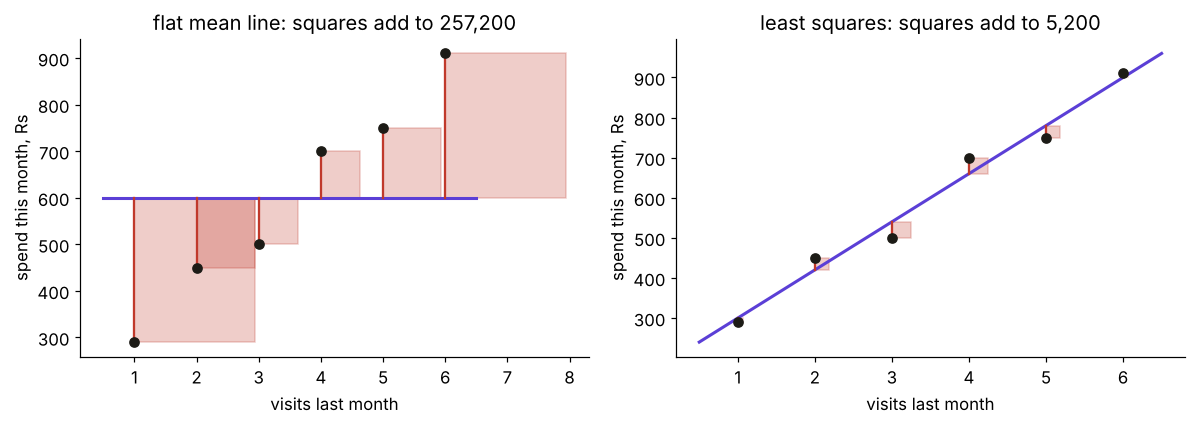

 visits  spend_rs  predicted  residual
      1       290      300.0     -10.0
      2       450      420.0      30.0
      3       500      540.0     -40.0
      4       700      660.0      40.0
      5       750      780.0     -30.0
      6       910      900.0      10.0
PASS  residuals of a least-squares line with an intercept sum to zero


In [5]:
# Draw the residuals as squares: the fit is the line whose squares add up smallest.
store["predicted"] = lin.predict(store[["visits"]])
store["residual"] = store["spend_rs"] - store["predicted"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, (a, b)) in zip((a1, a2), [("flat mean line", lines["flat mean line"]), ("least squares", lines["least squares"])]):
    pred = a + b * x
    ax.scatter(x, y, color="#1C1B16", zorder=3)
    ax.plot([0.5, 6.5], [a + b * 0.5, a + b * 6.5], color="#5B3FD6", lw=2)
    for xi, yi, pi in zip(x, y, pred):
        side = abs(yi - pi) / 160  # a square of side |residual|, drawn to the x-scale
        ax.add_patch(plt.Rectangle((xi, min(yi, pi)), side, abs(yi - pi), color="#C0392B", alpha=0.25))
        ax.plot([xi, xi], [yi, pi], color="#C0392B")
    ax.set_title(f"{name}: squares add to {sse(a, b):,.0f}"); ax.set_xlabel("visits last month"); ax.set_ylabel("spend this month, Rs")
plt.tight_layout(); plt.show()
print(store.to_string(index=False))
check("residuals of a least-squares line with an intercept sum to zero", abs(store["residual"].sum()) < 1e-6)

## What does the coefficient say, in rupees?

**Slope, Rs 120 per visit:** among these members, each extra visit last month goes with Rs 120 more spend this month. It is an association across members inside this fit. Whether getting a member to visit once more adds Rs 120 is a causal claim, and only an experiment (Week 1 Thursday) can back it.

**Intercept, Rs 180:** the line's value at zero visits. No member here made zero visits, so this is the line extended beyond its data, a number to quote with care.

**Residuals:** -10, +30, -40, +40, -30, +10. Small, mixed signs, no pattern: the straight line holds on these six points. Chapter 6 shows the residuals of a line that does not hold.

**Search it later as:** ordinary least squares, R squared. Here the line removes 98 percent of the squared error of the mean line (1 minus 5,200 / 257,200).

## What did this chapter establish?

| Question | Answer |
|---|---|
| What is the fitted line? | spend = Rs 180 + Rs 120 x visits |
| What makes it the best line? | the smallest sum of squared residuals, 5,200 against 5,480 by eye and 257,200 for the mean |
| What does the slope say? | Rs 120 more spend per extra visit, as an association, other things not held |
| What do the residuals say? | small and patternless here, so a line is enough |

**Interview line:** "Linear regression picks the line with the smallest sum of squared residuals; I read each coefficient in the target's units, say it is an association unless an experiment backs it, and look at the residuals before I trust the line."